# 03 — Comparación de modelos en igualdad de condiciones
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/03_comparacion_equitativa.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook creado después de la retroalimentación de la Segunda entrega (noviembre de 2026).

En la Segunda entrega solo Random Forest tuvo **pesos de clase** y **ajuste de hiperparámetros**; el árbol, AdaBoost y
Gradient Boosting quedaron con valores fijos y sin tratar el desbalance. Así, la conclusión "Random Forest es el más
robusto frente al desbalance" mezclaba el efecto del algoritmo con el efecto de esas dos ventajas.

Este notebook corrige eso (secciones **7.3–7.4** del enunciado):

| Condición | Árbol | Random Forest | AdaBoost | Gradient Boosting |
|---|---|---|---|---|
| Pesos de clase balanceados | `class_weight` | `class_weight` | `sample_weight` (vía `src/modelos_balanceados.py`) | `sample_weight` (vía `src/modelos_balanceados.py`) |
| Ajuste de hiperparámetros | GridSearchCV | GridSearchCV | GridSearchCV | GridSearchCV |
| Estimación del desempeño | CV anidada 5 × 3 | CV anidada 5 × 3 | CV anidada 5 × 3 | CV anidada 5 × 3 |
| Mismos datos, partición, Pipeline y pliegues | ✔ | ✔ | ✔ | ✔ |

La métrica para elegir es la **balanced accuracy** (la misma de las entregas anteriores).

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES = ROOT / "data", ROOT / "figuras", ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (balanced_accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)
from src.modelos_balanceados import AdaBoostBalanceado, GradientBoostingBalanceado

plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)
print(df.shape, f"mora = {df.incumple.mean():.2%}")

(6000, 11) mora = 8.50%


## 1. Partición y flujo (idénticos al notebook 02)
Misma partición estratificada 80/20 y mismo Pipeline `SimpleImputer(median) → StandardScaler → modelo`, que se ajusta
solo con datos de entrenamiento en cada pliegue. Los pesos de AdaBoost y Gradient Boosting se calculan **dentro** de
`fit`, con la proporción de clases del pliegue de entrenamiento, así que tampoco hay fuga por ese lado.

In [3]:
X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("classifier", model)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)       # GridSearch final
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)     # CV anidada: interna
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1) # CV anidada: externa (la misma para todos)
print(f"Train: {len(X_train)} | Test: {len(X_test)} | mora en ambos: {y_train.mean():.2%} / {y_test.mean():.2%}")

Train: 4800 | Test: 1200 | mora en ambos: 8.50% / 8.50%


## 2. Modelos y mallas de hiperparámetros
Cada malla cubre los parámetros que controlan la complejidad de cada modelo (ver la explicación de cada uno en el
informe). Random Forest usa la misma malla de la Segunda entrega.

| Modelo | Hiperparámetros explorados |
|---|---|
| Árbol | profundidad máxima {3, 5, 8, sin límite} × mínimo de registros por hoja {1, 10, 30} |
| Random Forest | árboles {100, 200} × profundidad {6, 8, 12} × mínimo para dividir {2, 5} × peso {balanced, balanced_subsample} |
| AdaBoost | árboles {100, 200, 400} × tasa de aprendizaje {0,25; 0,5; 1,0} (tocones de 1 nivel) |
| Gradient Boosting | árboles {100, 200, 400} × tasa de aprendizaje {0,02; 0,05; 0,1} × profundidad {1, 2, 3} |

In [4]:
candidatos = {
    "Árbol de Decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"classifier__max_depth": [3, 5, 8, None], "classifier__min_samples_leaf": [1, 10, 30]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED),
        {"classifier__n_estimators": [100, 200], "classifier__max_depth": [6, 8, 12],
         "classifier__min_samples_split": [2, 5], "classifier__class_weight": ["balanced", "balanced_subsample"]}),
    "AdaBoost": (
        AdaBoostBalanceado(random_state=SEED),
        {"classifier__n_estimators": [100, 200, 400], "classifier__learning_rate": [0.25, 0.5, 1.0]}),
    "Gradient Boosting": (
        GradientBoostingBalanceado(random_state=SEED),
        {"classifier__n_estimators": [100, 200, 400], "classifier__learning_rate": [0.02, 0.05, 0.1],
         "classifier__max_depth": [1, 2, 3]}),
}

## 3. Validación cruzada anidada (estimación honesta del desempeño)
En cada uno de los 5 pliegues externos se ejecuta un GridSearch interno (3 pliegues) solo con la parte de
entrenamiento de ese pliegue, y el modelo elegido se evalúa en el pliegue externo, que la búsqueda nunca vio.
Los pliegues externos son los mismos para todos los modelos, así que las diferencias se pueden comparar pliegue a pliegue.

In [5]:
anidada, por_pliegue, params_pliegue = [], {}, {}
for nombre, (modelo, malla) in candidatos.items():
    busqueda = GridSearchCV(make_pipe(modelo), malla, cv=inner, scoring="balanced_accuracy", n_jobs=-1)
    res = cross_validate(busqueda, X_train, y_train, cv=outer, scoring=["balanced_accuracy", "recall"],
                         return_estimator=True)
    por_pliegue[nombre] = res["test_balanced_accuracy"]
    params_pliegue[nombre] = [e.best_params_ for e in res["estimator"]]
    anidada.append({"Modelo": nombre,
                    "CV anidada Bal. Acc (media)": res["test_balanced_accuracy"].mean(),
                    "CV anidada Bal. Acc (desv)": res["test_balanced_accuracy"].std(),
                    "CV anidada Recall (media)": res["test_recall"].mean()})

tabla_anidada = pd.DataFrame(anidada).sort_values("CV anidada Bal. Acc (media)", ascending=False).round(4)
tabla_anidada

,Modelo,CV anidada Bal. Acc (media),CV anidada Bal. Acc (desv),CV anidada Recall (media)
1,Random Forest,0.8909,0.0109,0.9094
3,Gradient Boosting,0.8878,0.0066,0.8922
2,AdaBoost,0.8797,0.0154,0.8750
0,Árbol de Decisión,0.8572,0.0155,0.8727


### 3.1 Comparación pliegue a pliegue
Diferencia de cada modelo frente al mejor en cada pliegue externo. Si las diferencias cambian de signo entre pliegues
o son menores que la desviación entre pliegues, los modelos no se distinguen con estos datos.

In [6]:
pliegues = pd.DataFrame(por_pliegue, index=[f"Pliegue {k}" for k in range(1, 6)]).round(4)
mejor = tabla_anidada.iloc[0]["Modelo"]
dif = pliegues.sub(pliegues[mejor], axis=0).drop(columns=mejor)
display(pliegues)
print(f"Diferencia frente a {mejor} (negativo = peor que {mejor}):")
display(pd.concat([dif, dif.agg(["mean", "std"]).rename(index={"mean": "Media", "std": "Desv."})]).round(4))

,Árbol de Decisión,Random Forest,AdaBoost,Gradient Boosting
Pliegue 1,0.8371,0.8869,0.8534,0.8848
Pliegue 2,0.8821,0.8980,0.8970,0.8937
Pliegue 3,0.8471,0.8718,0.8733,0.8836
Pliegue 4,0.8652,0.9032,0.8834,0.8973
Pliegue 5,0.8547,0.8947,0.8913,0.8796


Diferencia frente a Random Forest (negativo = peor que Random Forest):


,Árbol de Decisión,AdaBoost,Gradient Boosting
Pliegue 1,-0.0498,-0.0335,-0.0021
Pliegue 2,-0.0159,-0.0010,-0.0043
Pliegue 3,-0.0247,0.0015,0.0118
Pliegue 4,-0.0380,-0.0198,-0.0059
Pliegue 5,-0.0400,-0.0034,-0.0151
Media,-0.0337,-0.0112,-0.0031
Desv.,0.0134,0.0150,0.0097


### 3.2 Estabilidad de los hiperparámetros elegidos en cada pliegue externo

In [7]:
for nombre, lista in params_pliegue.items():
    print(f"\n{nombre}")
    display(pd.DataFrame(lista).rename(columns=lambda c: c.replace("classifier__", "")))


Árbol de Decisión


,max_depth,min_samples_leaf
0,5,10
1,5,10
2,3,1
3,8,30
4,5,1



Random Forest


,class_weight,max_depth,min_samples_split,n_estimators
0,balanced,6,5,200
1,balanced,6,5,100
2,balanced,6,5,100
3,balanced,6,5,200
4,balanced,6,5,200



AdaBoost


,learning_rate,n_estimators
0,1.00,200
1,0.25,200
2,1.00,200
3,0.50,200
4,0.25,200



Gradient Boosting


,learning_rate,max_depth,n_estimators
0,0.05,2,200
1,0.10,1,400
2,0.10,1,200
3,0.10,1,400
4,0.10,1,100


## 4. Ajuste final y evaluación en el conjunto de prueba
Cada modelo se ajusta con GridSearch (5 pliegues) sobre todo el entrenamiento y se evalúa **una sola vez** en la
prueba, junto con la línea base.

In [8]:
finales, filas, scores = {}, [], {}

base = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
finales["Baseline (Mayoría)"] = base

for nombre, (modelo, malla) in candidatos.items():
    gs = GridSearchCV(make_pipe(modelo), malla, cv=cv5, scoring="balanced_accuracy", n_jobs=-1).fit(X_train, y_train)
    finales[nombre] = gs.best_estimator_
    print(f"{nombre:18s} mejores parámetros:",
          {k.replace("classifier__", ""): v for k, v in gs.best_params_.items()})

for nombre, modelo in finales.items():
    pred = modelo.predict(X_test)
    scores[nombre] = modelo.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Modelo": nombre,
                  "Test Bal. Acc": balanced_accuracy_score(y_test, pred),
                  "Test Recall": recall_score(y_test, pred, zero_division=0),
                  "Test Precision": precision_score(y_test, pred, zero_division=0),
                  "Test F1": f1_score(y_test, pred, zero_division=0),
                  "Test ROC-AUC": roc_auc_score(y_test, scores[nombre]),
                  "Morosos detectados": f"{tp} de {tp + fn}", "Falsas alarmas": fp})

tabla3 = (pd.DataFrame(filas).merge(tabla_anidada, on="Modelo", how="left")
          [["Modelo", "CV anidada Bal. Acc (media)", "CV anidada Bal. Acc (desv)", "Test Bal. Acc", "Test Recall",
            "Test Precision", "Test F1", "Test ROC-AUC", "Morosos detectados", "Falsas alarmas"]])
tabla3.round(4).to_csv(TABLES / "tabla3_comparacion_equitativa.csv", index=False)
tabla3.round(4)

Árbol de Decisión  mejores parámetros: {'max_depth': 5, 'min_samples_leaf': 10}


Random Forest      mejores parámetros: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_split': 5, 'n_estimators': 100}


AdaBoost           mejores parámetros: {'learning_rate': 1.0, 'n_estimators': 100}


Gradient Boosting  mejores parámetros: {'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 400}


,Modelo,CV anidada Bal. Acc (media),CV anidada Bal. Acc (desv),Test Bal. Acc,Test Recall,Test Precision,Test F1,Test ROC-AUC,Morosos detectados,Falsas alarmas
0,Baseline (Mayoría),NaN,NaN,0.5000,0.0000,0.0000,0.0000,0.5000,0 de 102,0
1,Árbol de Decisión,0.8572,0.0155,0.8573,0.8529,0.3640,0.5103,0.8747,87 de 102,152
2,Random Forest,0.8909,0.0109,0.8659,0.8529,0.3955,0.5404,0.9434,87 de 102,133
3,AdaBoost,0.8797,0.0154,0.8705,0.8529,0.4143,0.5577,0.9502,87 de 102,123
4,Gradient Boosting,0.8878,0.0066,0.8890,0.9020,0.4035,0.5576,0.9541,92 de 102,136


### 4.1 Antes y después de igualar las condiciones
Balanced accuracy en prueba de cada modelo en la Segunda entrega (sin pesos ni ajuste, salvo Random Forest) frente a
este notebook.

,Segunda entrega,Igualdad de condiciones,Cambio
Árbol de Decisión,0.7278,0.8573,0.1295
Random Forest,0.8659,0.8659,0.0000
AdaBoost,0.7124,0.8705,0.1581
Gradient Boosting,0.7547,0.8890,0.1343


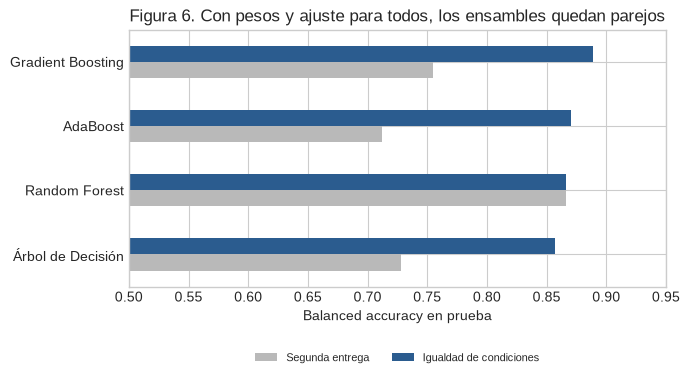

In [9]:
entrega2 = {"Árbol de Decisión": 0.7278, "Random Forest": 0.8659, "AdaBoost": 0.7124, "Gradient Boosting": 0.7547}
antes_despues = pd.DataFrame({
    "Segunda entrega": pd.Series(entrega2),
    "Igualdad de condiciones": tabla3.set_index("Modelo")["Test Bal. Acc"].reindex(list(entrega2)),
})
antes_despues["Cambio"] = antes_despues["Igualdad de condiciones"] - antes_despues["Segunda entrega"]
display(antes_despues.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
antes_despues[["Segunda entrega", "Igualdad de condiciones"]].plot(kind="barh", ax=ax, color=["#b9b9b9", "#2b5c8f"])
ax.set(xlim=(0.5, 0.95), xlabel="Balanced accuracy en prueba",
       title="Figura 6. Con pesos y ajuste para todos, los ensambles quedan parejos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIGS / "fig6_antes_despues_igualdad.png", dpi=300); plt.show()

## 5. Importancia de variables por permutación (modelo con mejor CV anidada)
La importancia MDI de la Segunda entrega se calcula con los datos de entrenamiento y favorece a las variables
continuas. La **importancia por permutación** mide cuánto cae la balanced accuracy **en la prueba** cuando se
desordena una variable: si cae mucho, el modelo depende de ella.

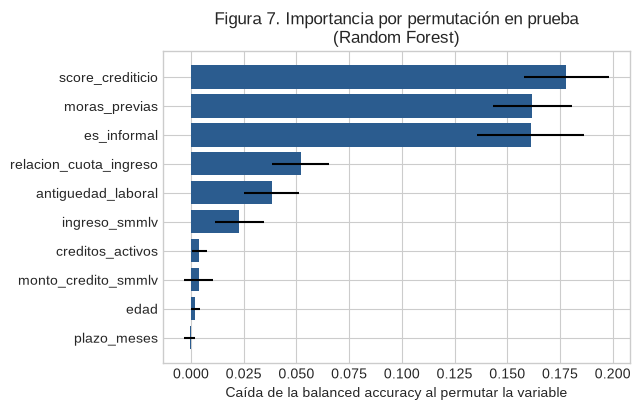

,media,desv
score_crediticio,0.1779,0.0202
moras_previas,0.1619,0.0188
es_informal,0.1611,0.0254
relacion_cuota_ingreso,0.0520,0.0135
antiguedad_laboral,0.0382,0.0132
ingreso_smmlv,0.0229,0.0116
creditos_activos,0.0040,0.0036
monto_credito_smmlv,0.0037,0.0068
edad,0.0021,0.0023
plazo_meses,-0.0006,0.0027


In [10]:
elegido = tabla_anidada.iloc[0]["Modelo"]
perm = permutation_importance(finales[elegido], X_test, y_test, scoring="balanced_accuracy",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"media": perm.importances_mean, "desv": perm.importances_std},
                   index=X.columns).sort_values("media")
imp.round(4).to_csv(TABLES / "importancia_permutacion.csv")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(imp.index, imp["media"], xerr=imp["desv"], color="#2b5c8f")
ax.set(title=f"Figura 7. Importancia por permutación en prueba\n({elegido})",
       xlabel="Caída de la balanced accuracy al permutar la variable")
plt.tight_layout(); plt.savefig(FIGS / "fig7_importancia_permutacion.png", dpi=300); plt.show()
imp.sort_values("media", ascending=False).round(4)

## 6. ¿Dónde se equivoca el modelo? Errores por tipo de empleo
Se cruzan los errores del modelo elegido en la prueba con el segmento laboral del solicitante.

In [11]:
pred = finales[elegido].predict(X_test)
errores = pd.DataFrame({"segmento": np.where(X_test["es_informal"] == 1, "Informal", "Formal"),
                        "real": y_test.values, "pred": pred})
filas_seg = []
for seg, g in errores.groupby("segmento"):
    filas_seg.append({"Segmento": seg, "Solicitantes": len(g),
                      "Morosos reales": int((g.real == 1).sum()),
                      "Morosos detectados": int(((g.real == 1) & (g.pred == 1)).sum()),
                      "Morosos no detectados (FN)": int(((g.real == 1) & (g.pred == 0)).sum()),
                      "Falsas alarmas (FP)": int(((g.real == 0) & (g.pred == 1)).sum()),
                      "% de buenos clientes rechazados": round(100 * ((g.real == 0) & (g.pred == 1)).sum() / (g.real == 0).sum(), 1),
                      "% de solicitudes rechazadas": round(100 * (g.pred == 1).mean(), 1)})
resumen = pd.DataFrame(filas_seg).set_index("Segmento")
resumen

,Solicitantes,Morosos reales,Morosos detectados,Morosos no detectados (FN),Falsas alarmas (FP),% de buenos clientes rechazados,% de solicitudes rechazadas
Segmento,,,,,,,
Formal,519,1,0,1,0,0.0,0.0
Informal,681,101,87,14,133,22.9,32.3


## 7. Lectura

**1. Con pesos y ajuste para todos, los ensambles quedan parejos.** En la CV anidada, Random Forest (0,891 ± 0,011),
Gradient Boosting (0,888 ± 0,007) y AdaBoost (0,880 ± 0,015) quedan a menos de una desviación estándar entre sí, y en
la comparación pliegue a pliegue la diferencia frente a Random Forest cambia de signo (Gradient Boosting: −0,003 ± 0,010;
AdaBoost: −0,011 ± 0,015). Con estos datos no se puede afirmar que uno sea mejor que otro. El árbol individual sí queda
por debajo en los cinco pliegues (−0,034 ± 0,013).

**2. Corrige la conclusión de la Segunda entrega.** La ventaja de Random Forest venía sobre todo de que era el único
modelo con pesos de clase y ajuste: al darles las mismas condiciones, AdaBoost sube 0,16 de balanced accuracy en
prueba, Gradient Boosting 0,13 y el árbol 0,13 (Figura 6). Lo que importaba era tratar el desbalance, no el tipo de
ensamble.

**3. Coincide con el artículo en el orden, no en la distancia.** Como en Koshti et al. (2025), Random Forest queda
primero en la estimación principal y los ensambles superan al árbol individual; pero aquí la distancia entre ensambles
es pequeña y no significativa.

**4. Modelo de referencia para la entrega final.** Con el criterio declarado (mayor balanced accuracy en CV anidada) se
mantiene **Random Forest**, que además elige los mismos hiperparámetros en los cinco pliegues (profundidad 6, mínimo
para dividir 5, `class_weight='balanced'`). Gradient Boosting es la alternativa más fuerte: mejor resultado en prueba
(0,889 y 92 de 102 morosos detectados) y la menor variación entre pliegues, aunque sus hiperparámetros cambian de un
pliegue a otro y su mejor configuración final queda en el borde de la malla (400 árboles de un nivel). La elección
definitiva, con ajuste del umbral de decisión e interpretación con SHAP, queda para la entrega final.

**5. Variables relevantes.** La importancia por permutación en prueba confirma el orden de la Figura 5: `score_crediticio`,
`moras_previas` y `es_informal` dominan, seguidas de `relacion_cuota_ingreso` y `antiguedad_laboral`. Las variables de
control que no entran en la simulación de la mora (`edad`, `plazo_meses`, `creditos_activos`) tienen importancia casi
nula, lo que indica que el modelo no aprende ruido.

**6. Implicación práctica: los errores recaen en los informales.** En la prueba, el modelo no rechaza a ningún
solicitante formal, mientras que rechaza al 32 % de los informales; las 133 falsas alarmas son todas de clientes
informales que sí pagan (≈ 23 % de los informales al día). Es la consecuencia directa de la limitación de la simulación
documentada en el notebook 01 (mora formal casi nula), y es justo el riesgo social planteado en la Primera entrega:
excluir del crédito a población informal solvente. Debe tenerse en cuenta al fijar el umbral y al interpretar el modelo
en la entrega final.